# Signal 2 default model

Stand-in for Lender 2 in the team's market simulation: shared features plus `signal2`. This notebook compares default models on the shared train split and scores them once on the test split. New applicants only have `signal3`, so this model is not used to price them; it is a benchmark for the report.

- `sex` is not used as a feature.
- `signal1` and `signal3` are not used.

| Decision | Options | Evidence | Course / team link | Choice |
|---|---|---|---|---|
| D1: income encoding | (a) raw, (b) log, (c) log + zero flag, (d) (c) with income floored at 2,000 € | CV log loss 0.2921 / 0.3041 / 0.2927 / 0.2914; (c) predicts 77% vs 26% observed for incomes of 1 to 500 € | Unbiased PD (Session 8); signal3 uses log + zero flag | (d) |
| D2: `signal2_zero` flag | keep, drop | 0.2914 vs 0.2928, a gap of about one CV std | `signal2 = 0` default rate is close to average; ties go to the simpler option | Drop |
| D4: recalibration | none, recalibrate | Out-of-fold slope 0.991 to 1.005, intercept close to 0 for every model | signal3 did not recalibrate | None |
| D5: exported model | logreg, spline logreg, XGBoost, CatBoost | XGBoost 0.2907, CatBoost 0.2909, spline 0.2913 (tie); logreg 0.2928 | Explainability (ISAF); ties go to the simpler option | Spline logreg |


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
import xgboost as xgb
from catboost import CatBoostClassifier, Pool
from catboost import cv as catboost_cv
from catboost import __version__ as catboost_version
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler

SEED = 42
PROCESSED_DIR = Path("../data/processed")
COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]  # Okabe-Ito, colorblind-safe

TARGET = "default"

# Same 5 CV folds on train for every model; the test split is never used for tuning
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Seed: {SEED} | scikit-learn {sklearn.__version__}, xgboost {xgb.__version__}, "
      f"catboost {catboost_version}, optuna {optuna.__version__}")

/Users/laikhuramkorouhanbakhuman/Projects/Happiness-in-your-Household/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Seed: 42 | scikit-learn 1.9.1, xgboost 3.4.1, catboost 1.2.10, optuna 5.0.0


## 1. Load the shared split

In [2]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

for name, part in [("train", train), ("test", test)]:
    print(f"{name}: {len(part):,} rows, default rate {part[TARGET].mean():.2%}")

# Check the files come from the shared split
assert (len(train), len(test)) == (70_000, 30_000), "unexpected split sizes: re-run eda_and_split.ipynb"
assert not set(train["id"]) & set(test["id"]), "a borrower appears in both train and test"
assert round(train[TARGET].mean(), 4) == round(test[TARGET].mean(), 4) == 0.0995, (
    "default rate has drifted from the shared split's 9.95%"
)

train: 70,000 rows, default rate 9.95%
test: 30,000 rows, default rate 9.95%


## 2. Default rate by `signal2` bin

Train only, same bins as the EDA: exactly 0, then deciles of the positive values.

In [3]:
is_zero = train["signal2"] == 0
zero_share = is_zero.mean()
default_rate_zero = train.loc[is_zero, TARGET].mean()
default_rate_positive = train.loc[~is_zero, TARGET].mean()

summary = pd.DataFrame({
    "share_zero": [zero_share],
    "default_rate_if_zero": [default_rate_zero],
    "default_rate_if_positive": [default_rate_positive],
}, index=["signal2"])
summary.round(3)

,share_zero,default_rate_if_zero,default_rate_if_positive
signal2,0.209,0.099,0.1


In [4]:
positive = train[train["signal2"] > 0]
decile = pd.qcut(positive["signal2"], 10, labels=False) + 1
rate_by_decile = positive.groupby(decile)[TARGET].mean() * 100
overall_rate = train[TARGET].mean() * 100

bins = pd.DataFrame({
    "bin": range(11),
    "label": ["0 (exactly zero)"] + [f"decile {i}" for i in range(1, 11)],
    "default_rate_pct": [default_rate_zero * 100, *rate_by_decile.values],
})
bins.round(2)

,bin,label,default_rate_pct
0,0,0 (exactly zero),9.90
1,1,decile 1,15.62
2,2,decile 2,12.91
3,3,decile 3,10.46
4,4,decile 4,11.05
5,5,decile 5,9.48
6,6,decile 6,8.34
7,7,decile 7,7.64
8,8,decile 8,8.20
9,9,decile 9,7.91


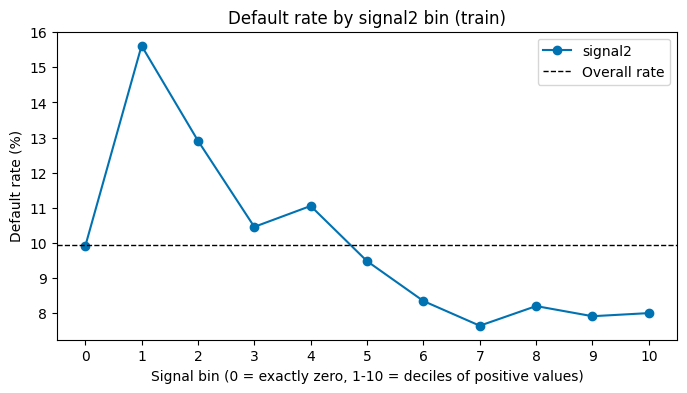

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(bins["bin"], bins["default_rate_pct"], marker="o", color=COLORS[0], label="signal2")
ax.axhline(overall_rate, color="black", ls="--", lw=1, label="Overall rate")
ax.set(title="Default rate by signal2 bin (train)",
       xlabel="Signal bin (0 = exactly zero, 1-10 = deciles of positive values)",
       ylabel="Default rate (%)", xticks=range(11))
ax.legend()
plt.show()

About 21% of `signal2` is exactly 0, with a default rate (9.9%) close to the overall rate. Among positive values the lowest decile is the riskiest (15.6%), and the rate then falls to about 8%, so the relationship is less monotonic than the EDA summary for the three signals.

## 3. Small incomes

Default rate for incomes between 1 and 2,000 €, to set the floor used in income option (d).

In [6]:
tiny = train[(train["income"] >= 1) & (train["income"] <= 2000)]
edges = list(range(0, 2001, 200))
edges[0] = 1  # bins start at 1 euro, not 0 (0 is its own group, handled separately)
tiny_bins = pd.cut(tiny["income"], bins=edges, include_lowest=True)

tiny_table = tiny.groupby(tiny_bins, observed=False)[TARGET].agg(["mean", "count"])
tiny_table["mean"] = (tiny_table["mean"] * 100).round(2)
tiny_table = tiny_table.rename(columns={"mean": "default_rate_pct"})

print(f"Loans with income in (0, 2000]: {len(tiny):,} out of {len(train):,} "
      f"({len(tiny) / len(train):.2%})")
print(f"Default rate if income == 0: {train.loc[train['income'] == 0, TARGET].mean():.2%} "
      f"(n={ (train['income'] == 0).sum():,})")
print(f"Overall default rate: {train[TARGET].mean():.2%}")
tiny_table

Loans with income in (0, 2000]: 295 out of 70,000 (0.42%)
Default rate if income == 0: 20.18% (n=11,905)
Overall default rate: 9.95%


,default_rate_pct,count
income,,
"(0.999, 200.0]",26.92,26
"(200.0, 400.0]",25.00,36
"(400.0, 600.0]",37.50,32
"(600.0, 800.0]",19.44,36
"(800.0, 1000.0]",18.75,32
"(1000.0, 1200.0]",16.13,31
"(1200.0, 1400.0]",25.00,36
"(1400.0, 1600.0]",4.55,22
"(1600.0, 1800.0]",4.17,24


Only 295 loans (0.4%) fall in this range, so each bin is noisy, but nearly every bin is well above the overall rate (9.95%) and close to the zero-income group (20.2%). Income is floored at 2,000 € before the log; this is below the 1st percentile of positive incomes (about 2,730 €).

## 4. Features

These transforms work row by row and learn nothing from the data, so they are applied identically to train and test:

- `employment` one-hot encoded: the linear models drop `employed` as the reference level, XGBoost gets all four, CatBoost uses the raw column
- `log_income_floored = log(1 + max(income, 2000))` plus a `zero_income` flag; raw and plain log income are kept for the D1 comparison
- `signal2`, plus a `signal2_zero` flag (tested in D2)

Scaling and spline knots sit inside each model's pipeline, so they are fit on the training folds only.

In [7]:
EMPLOYMENT_LEVELS = ["employed", "retired", "student", "unemployed"]
EMPLOYMENT_ALL = [f"employment_{level}" for level in EMPLOYMENT_LEVELS]
EMPLOYMENT_DUMMIES = EMPLOYMENT_ALL[1:]  # linear models: "employed" is the reference level
FLOOR = 2000  # euros; chosen above from the data, not guessed


def prepare(df: pd.DataFrame) -> pd.DataFrame:
    """Model features of a loans table (row-wise, nothing fitted)."""
    unknown = set(df["employment"]) - set(EMPLOYMENT_LEVELS)
    assert not unknown, f"unknown employment levels: {unknown}"
    X = pd.DataFrame(index=df.index)
    X["employment"] = df["employment"]  # raw column, for CatBoost later
    for level, col in zip(EMPLOYMENT_LEVELS, EMPLOYMENT_ALL):
        X[col] = (df["employment"] == level).astype(int)
    X["married"] = df["married"]
    X["income"] = df["income"]
    X["log_income"] = np.log1p(df["income"])
    X["income_floored"] = df["income"].clip(lower=FLOOR)
    X["log_income_floored"] = np.log1p(X["income_floored"])
    X["zero_income"] = (df["income"] == 0).astype(int)
    X["signal2"] = df["signal2"]
    X["signal2_zero"] = (df["signal2"] == 0).astype(int)
    return X


X_train, y_train = prepare(train), train[TARGET]
X_test, y_test = prepare(test), test[TARGET]
folds = list(CV.split(X_train, y_train))  # same 5 folds reused for every experiment below

X_train.head()

,employment,employment_employed,employment_retired,employment_student,employment_unemployed,married,income,log_income,income_floored,log_income_floored,zero_income,signal2,signal2_zero
0,employed,1,0,0,0,1,15064,9.620129,15064,9.620129,0,0.913391,0
1,employed,1,0,0,0,0,6816,8.827175,6816,8.827175,0,0.541121,0
2,student,0,0,1,0,0,0,0.000000,2000,7.601402,1,0.377906,0
3,employed,1,0,0,0,1,28404,10.254320,28404,10.254320,0,0.630580,0
4,employed,1,0,0,0,0,7030,8.858084,7030,8.858084,0,0.805111,0


## 5. Income encoding (D1)

Four income versions, each in a logistic regression with C tuned on CV log loss; only the income columns change between runs.

- (a) raw income
- (b) log(1 + income)
- (c) log(1 + income) + `zero_income` flag
- (d) as (c), with income floored at 2,000 € before the log

In [8]:
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
BASE_BINARY = EMPLOYMENT_DUMMIES + ["married", "signal2_zero"]


def fit_variant(continuous: list[str], binary: list[str]) -> GridSearchCV:
    """Grid-search C for a logistic regression pipeline on the given feature lists."""
    pipe = Pipeline([
        ("prep", ColumnTransformer([
            ("num", StandardScaler(), continuous),
            ("bin", "passthrough", binary),
        ])),
        ("model", LogisticRegression(max_iter=1000)),
    ])
    return GridSearchCV(pipe, {"model__C": C_GRID}, cv=CV, scoring="neg_log_loss").fit(X_train, y_train)


def summarize(search: GridSearchCV) -> dict[str, float]:
    best = search.best_index_
    return {
        "cv_log_loss_mean": -search.best_score_,
        "cv_log_loss_std": search.cv_results_["std_test_score"][best],
        "best_C": search.best_params_["model__C"],
    }


income_variants = {
    "a_raw_income": (["income", "signal2"], BASE_BINARY),
    "b_log_income": (["log_income", "signal2"], BASE_BINARY),
    "c_log_income_plus_zero_flag": (["log_income", "signal2"], BASE_BINARY + ["zero_income"]),
    "d_floored_log_income_plus_zero_flag": (["log_income_floored", "signal2"], BASE_BINARY + ["zero_income"]),
}

income_searches = {name: fit_variant(*cols) for name, cols in income_variants.items()}
income_results = pd.DataFrame({name: summarize(s) for name, s in income_searches.items()}).T
income_results.round(4)

,cv_log_loss_mean,cv_log_loss_std,best_C
a_raw_income,0.2921,0.0012,10.0
b_log_income,0.3041,0.0012,1.0
c_log_income_plus_zero_flag,0.2927,0.0011,1000.0
d_floored_log_income_plus_zero_flag,0.2914,0.0012,1.0


### Calibration for small incomes

Out-of-fold mean predicted PD vs observed default rate per income band. A small group can be badly mispredicted without moving the average CV log loss.

In [9]:
def oof_predict(search: GridSearchCV) -> np.ndarray:
    """Out-of-fold PDs on train, using the tuned pipeline refit on each training fold."""
    estimator = search.best_estimator_
    oof = np.zeros(len(y_train))
    for fit_idx, val_idx in folds:
        model = clone(estimator).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        oof[val_idx] = model.predict_proba(X_train.iloc[val_idx])[:, 1]
    return oof


def income_band(income: pd.Series) -> pd.Series:
    conditions = [income == 0, income < 500, income < 2000, income < 5000]
    choices = ["0", "1-500", "500-2000", "2000-5000"]
    return pd.Series(np.select(conditions, choices, default="above 5000"), index=income.index)


BAND_ORDER = ["0", "1-500", "500-2000", "2000-5000", "above 5000"]
bands = income_band(X_train["income"])
oof_preds = {name: oof_predict(search) for name, search in income_searches.items()}

calibration = pd.DataFrame({"observed": y_train.values, **oof_preds}, index=X_train.index)
calibration_by_band = (calibration.groupby(bands).mean() * 100).reindex(BAND_ORDER)
calibration_by_band["count"] = bands.value_counts().reindex(BAND_ORDER)
calibration_by_band.round(2)

,observed,a_raw_income,b_log_income,c_log_income_plus_zero_flag,d_floored_log_income_plus_zero_flag,count
0,20.18,19.61,21.78,20.18,20.20,11905
1-500,25.97,18.91,16.72,76.70,29.22,77
500-2000,18.35,17.42,12.29,39.14,29.28,218
2000-5000,14.63,13.93,8.85,14.73,16.59,3972
above 5000,7.28,7.47,7.39,7.12,7.09,53828


## 6. `signal2_zero` flag (D2)

Best income version, with and without the flag.

In [10]:
best_income = income_results["cv_log_loss_mean"].idxmin()
print(f"Lowest CV log loss among the income options: {best_income}")

best_continuous, best_binary_with_flag = income_variants[best_income]
best_binary_without_flag = [b for b in best_binary_with_flag if b != "signal2_zero"]

signal2_variants = {
    "with_signal2_zero": (best_continuous, best_binary_with_flag),
    "without_signal2_zero": (best_continuous, best_binary_without_flag),
}
signal2_searches = {name: fit_variant(*cols) for name, cols in signal2_variants.items()}
signal2_results = pd.DataFrame({name: summarize(s) for name, s in signal2_searches.items()}).T
signal2_results.round(4)

Lowest CV log loss among the income options: d_floored_log_income_plus_zero_flag


,cv_log_loss_mean,cv_log_loss_std,best_C
with_signal2_zero,0.2914,0.0012,1.0
without_signal2_zero,0.2928,0.0012,1.0


## 7. Selected features

- D1: option (d). Lowest CV log loss, and the only version without a large error for small incomes.
- D2: flag dropped. The gain (0.0014) is about the size of the CV std.

In [11]:
FEATURES_CONTINUOUS = ["log_income_floored", "signal2"]
FEATURES_BINARY = EMPLOYMENT_DUMMIES + ["married", "zero_income"]

final = signal2_searches["without_signal2_zero"]
print(f"Continuous: {FEATURES_CONTINUOUS}")
print(f"Binary: {FEATURES_BINARY}")
print(f"CV log loss with this feature set: {signal2_results.loc['without_signal2_zero', 'cv_log_loss_mean']:.4f} "
      f"(std {signal2_results.loc['without_signal2_zero', 'cv_log_loss_std']:.4f})")

Continuous: ['log_income_floored', 'signal2']
Binary: ['employment_retired', 'employment_student', 'employment_unemployed', 'married', 'zero_income']
CV log loss with this feature set: 0.2928 (std 0.0012)


## 8. Models

Five models on the same 5 CV folds, each scored once on the test split. The linear models use the features selected above.

### Baseline

In [12]:
def evaluate(y_true: np.ndarray, p_pred: np.ndarray) -> dict[str, float]:
    """Log loss, Brier score and AUC of predicted default probabilities."""
    return {
        "log_loss": log_loss(y_true, p_pred),
        "brier": brier_score_loss(y_true, p_pred),
        "auc": roc_auc_score(y_true, p_pred),
    }


def record(name: str, cv_scores: tuple[float, float], p_test: np.ndarray) -> None:
    """Store CV log loss (mean, std) and test scores of a model."""
    test_probs[name] = p_test
    results[name] = {"cv_log_loss": cv_scores[0], "cv_std": cv_scores[1], **evaluate(y_test, p_test)}


def sklearn_fitter(estimator):
    """Fit function for a tuned sklearn estimator: refits a copy and returns its PD predictor."""
    def fit(X: pd.DataFrame, y: pd.Series):
        model = clone(estimator).fit(X, y)
        return lambda Z: model.predict_proba(Z)[:, 1]
    return fit


results = {}
test_probs = {}
fitters = {}  # model name -> fit(X, y) returning a PD predictor, with the tuned settings

ALL_FEATURES = FEATURES_CONTINUOUS + FEATURES_BINARY
dummy = DummyClassifier(strategy="prior")
dummy_cv = -cross_val_score(dummy, X_train[ALL_FEATURES], y_train, cv=CV, scoring="neg_log_loss")
record("dummy (prior)", (dummy_cv.mean(), dummy_cv.std()),
       dummy.fit(X_train[ALL_FEATURES], y_train).predict_proba(X_test[ALL_FEATURES])[:, 1])

pd.DataFrame(results).T.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5


### Logistic regression

Reuses the D2 grid search on the selected features (C tuned on CV log loss).

In [13]:
record("logreg", (-final.best_score_, final.cv_results_["std_test_score"][final.best_index_]),
       final.predict_proba(X_test)[:, 1])
fitters["logreg"] = sklearn_fitter(final.best_estimator_)
print(f"Best C: {final.best_params_['model__C']}")

pd.DataFrame(results).T.round(4)

Best C: 1


,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000
logreg,0.2928,0.0012,0.2935,0.0844,0.7261


### Spline logistic regression

Cubic splines on `log_income_floored` and `signal2`, binary features passed through. Number of knots and C tuned by grid search on CV log loss.

In [14]:
spline_pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("spline", SplineTransformer(degree=3, knots="quantile"), FEATURES_CONTINUOUS),
        ("bin", "passthrough", FEATURES_BINARY),
    ])),
    ("model", LogisticRegression(max_iter=2000)),
])
spline_grid = {"prep__spline__n_knots": [4, 6, 8, 10, 12], "model__C": [0.1, 1, 10, 100, 1000, 10000]}
spline_search = GridSearchCV(spline_pipe, spline_grid, cv=CV, scoring="neg_log_loss").fit(X_train, y_train)

best = spline_search.best_index_
record("spline logreg", (-spline_search.best_score_, spline_search.cv_results_["std_test_score"][best]),
       spline_search.predict_proba(X_test)[:, 1])
fitters["spline logreg"] = sklearn_fitter(spline_search.best_estimator_)
print(f"Best settings: {spline_search.best_params_}")

pd.DataFrame(results).T.round(4)

Best settings: {'model__C': 10, 'prep__spline__n_knots': 10}


,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000
logreg,0.2928,0.0012,0.2935,0.0844,0.7261
spline logreg,0.2913,0.0010,0.2914,0.0838,0.7332


### Tree features

Trees split on raw values and can isolate income = 0 with one split, so XGBoost and CatBoost get plain `income` and `signal2` with no transform or flag, as in `signal3_models.ipynb`.

In [15]:
TREE_FEATURES = EMPLOYMENT_ALL + ["married", "income", "signal2"]
CATBOOST_FEATURES = ["employment", "married", "income", "signal2"]
CATBOOST_CATEGORICAL = ["employment"]
N_TRIALS = 40
optuna.logging.set_verbosity(optuna.logging.WARNING)

### XGBoost

Optuna tunes the hyperparameters on the same 5-fold CV log loss; early stopping sets the
number of trees.

In [16]:
dtrain = xgb.DMatrix(X_train[TREE_FEATURES], label=y_train)
XGB_BASE = {"objective": "binary:logistic", "eval_metric": "logloss", "tree_method": "hist", "seed": SEED}


def xgb_objective(trial: optuna.Trial) -> float:
    params = XGB_BASE | {
        "eta": trial.suggest_float("eta", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 200, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "lambda": trial.suggest_float("lambda", 1e-3, 10, log=True),
        "gamma": trial.suggest_float("gamma", 1e-4, 5, log=True),
    }
    cv = xgb.cv(params, dtrain, num_boost_round=2000, folds=folds, early_stopping_rounds=50, verbose_eval=False)
    trial.set_user_attr("n_rounds", len(cv))
    trial.set_user_attr("cv_std", cv["test-logloss-std"].iloc[-1])
    return cv["test-logloss-mean"].iloc[-1]


xgb_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
xgb_study.optimize(xgb_objective, n_trials=N_TRIALS)

xgb_params = XGB_BASE | xgb_study.best_params
xgb_rounds = xgb_study.best_trial.user_attrs["n_rounds"]
print(f"Best CV log loss {xgb_study.best_value:.4f} with {xgb_rounds} trees: {xgb_study.best_params}")


def fit_xgb(X: pd.DataFrame, y: pd.Series):
    """Train XGBoost with the tuned settings; returns its PD predictor."""
    booster = xgb.train(xgb_params, xgb.DMatrix(X[TREE_FEATURES], label=y), num_boost_round=xgb_rounds)
    return lambda Z: booster.predict(xgb.DMatrix(Z[TREE_FEATURES]))


fitters["xgboost"] = fit_xgb

Best CV log loss 0.2907 with 832 trees: {'eta': 0.017476752399097042, 'max_depth': 2, 'min_child_weight': 1.0270096070719164, 'subsample': 0.5540657789000165, 'colsample_bytree': 0.9033065957181308, 'lambda': 0.1938242099818816, 'gamma': 0.430295380175297}


### CatBoost

CatBoost uses `employment` as a categorical feature directly. Optuna tunes it on the same
folds and CV log loss; early stopping sets the number of trees.

In [17]:
train_pool = Pool(X_train[CATBOOST_FEATURES], label=y_train, cat_features=CATBOOST_CATEGORICAL)
CB_BASE = {"loss_function": "Logloss", "bootstrap_type": "Bernoulli", "random_seed": SEED,
           "logging_level": "Silent", "allow_writing_files": False}


def catboost_objective(trial: optuna.Trial) -> float:
    params = CB_BASE | {
        "iterations": 2000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "depth": trial.suggest_int("depth", 2, 8),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1e-2, 30, log=True),
        "random_strength": trial.suggest_float("random_strength", 1e-3, 10, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
    }
    cv = catboost_cv(train_pool, params, folds=folds, early_stopping_rounds=50)
    best_iter = cv["test-Logloss-mean"].idxmin()
    trial.set_user_attr("n_rounds", int(cv.loc[best_iter, "iterations"]) + 1)
    trial.set_user_attr("cv_std", cv.loc[best_iter, "test-Logloss-std"])
    return cv.loc[best_iter, "test-Logloss-mean"]


cb_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
cb_study.optimize(catboost_objective, n_trials=N_TRIALS)

cb_params = CB_BASE | cb_study.best_params
cb_rounds = cb_study.best_trial.user_attrs["n_rounds"]
print(f"Best CV log loss {cb_study.best_value:.4f} with {cb_rounds} trees: {cb_study.best_params}")


def fit_catboost(X: pd.DataFrame, y: pd.Series):
    """Train CatBoost with the tuned settings; returns its PD predictor."""
    model = CatBoostClassifier(**cb_params, iterations=cb_rounds)
    model.fit(X[CATBOOST_FEATURES], y, cat_features=CATBOOST_CATEGORICAL)
    return lambda Z: model.predict_proba(Z[CATBOOST_FEATURES])[:, 1]


fitters["catboost"] = fit_catboost

Best CV log loss 0.2909 with 1999 trees: {'learning_rate': 0.010093006737080365, 'depth': 4, 'l2_leaf_reg': 0.04910060030157179, 'random_strength': 2.155465286584013, 'subsample': 0.9940697192199495}


### Test scores for the boosted models

In [18]:
record("xgboost", (xgb_study.best_value, xgb_study.best_trial.user_attrs["cv_std"]),
       fit_xgb(X_train, y_train)(X_test))
record("catboost", (cb_study.best_value, cb_study.best_trial.user_attrs["cv_std"]),
       fit_catboost(X_train, y_train)(X_test))

pd.DataFrame(results).T.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000
logreg,0.2928,0.0012,0.2935,0.0844,0.7261
spline logreg,0.2913,0.0010,0.2914,0.0838,0.7332
xgboost,0.2907,0.0012,0.2912,0.0838,0.7340
catboost,0.2909,0.0013,0.2910,0.0837,0.7343


## 9. Comparison

Sorted by CV log loss. XGBoost, CatBoost and spline logistic regression are within one CV std of each other; logistic regression is about 0.002 behind.

In [19]:
comparison = pd.DataFrame(results).T.sort_values("cv_log_loss")
comparison.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
xgboost,0.2907,0.0012,0.2912,0.0838,0.7340
catboost,0.2909,0.0013,0.2910,0.0837,0.7343
spline logreg,0.2913,0.0010,0.2914,0.0838,0.7332
logreg,0.2928,0.0012,0.2935,0.0844,0.7261
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000


## 10. Calibration

A model is calibrated if, among borrowers given a PD of 30%, about 30% default. This matters more than AUC here: expected profit per euro is R - P[default], so pricing uses the PD level, not only the ranking.

Checked out of fold on train (slope and intercept from regressing the outcome on logit(PD)), then on the test split by decile and by `signal2` bin.

In [20]:
def oof_predictions(fit, X: pd.DataFrame, y: pd.Series) -> np.ndarray:
    """Out-of-fold PDs on train: fit on 4 folds, predict the 5th."""
    oof = np.zeros(len(y))
    for fit_idx, val_idx in folds:
        predict = fit(X.iloc[fit_idx], y.iloc[fit_idx])
        oof[val_idx] = predict(X.iloc[val_idx])
    return oof


def calibration_slope(y_true: np.ndarray, p_pred: np.ndarray) -> tuple[float, float]:
    """Calibration slope and intercept from refitting y on logit(p)."""
    p = np.clip(p_pred, 1e-6, 1 - 1e-6)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    fit = LogisticRegression(C=1e6).fit(logit, y_true)
    return fit.coef_[0][0], fit.intercept_[0]


oof_preds = {name: oof_predictions(fit, X_train, y_train) for name, fit in fitters.items()}

for name, oof in oof_preds.items():
    slope, intercept = calibration_slope(y_train.values, oof)
    print(f"{name}: mean predicted {oof.mean():.2%} vs observed {y_train.mean():.2%} | "
          f"slope {slope:.3f}, intercept {intercept:.3f}")

logreg: mean predicted 9.94% vs observed 9.95% | slope 0.998, intercept -0.004
spline logreg: mean predicted 9.95% vs observed 9.95% | slope 0.991, intercept -0.016
xgboost: mean predicted 9.95% vs observed 9.95% | slope 1.005, intercept 0.008
catboost: mean predicted 9.96% vs observed 9.95% | slope 0.999, intercept -0.004


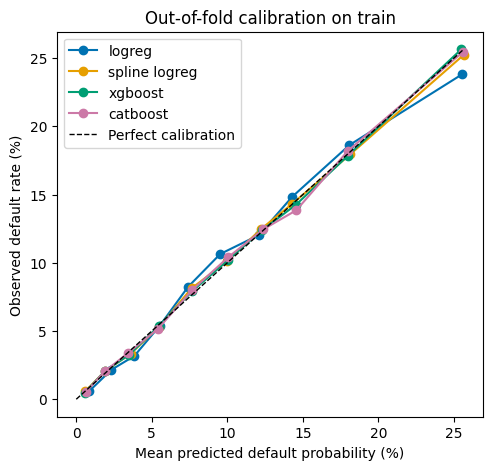

In [21]:
def plot_calibration(y_true: np.ndarray, probs: dict[str, np.ndarray],
                      title: str = "Calibration", n_bins: int = 10) -> None:
    """Plot observed default rate vs mean predicted probability per quantile bin."""
    _, ax = plt.subplots(figsize=(5.5, 5))
    top = 0.0
    for (name, p), color in zip(probs.items(), COLORS):
        observed, predicted = calibration_curve(y_true, p, n_bins=n_bins, strategy="quantile")
        ax.plot(predicted * 100, observed * 100, marker="o", color=color, label=name)
        top = max(top, predicted.max(), observed.max())
    ax.plot([0, top * 100], [0, top * 100], ls="--", lw=1, color="black", label="Perfect calibration")
    ax.set(title=title, xlabel="Mean predicted default probability (%)", ylabel="Observed default rate (%)")
    ax.legend()
    plt.show()


plot_calibration(y_train, oof_preds, title="Out-of-fold calibration on train")

### Test split: deciles

Mean predicted PD vs observed default rate per decile of each model's PD.

In [22]:
def decile_table(y_true: pd.Series, p: np.ndarray) -> pd.DataFrame:
    decile = pd.qcut(p, 10, labels=False, duplicates="drop") + 1
    return (pd.DataFrame({"observed": y_true.values, "predicted": p}, index=y_true.index)
            .groupby(decile).mean() * 100)


test_probs_no_dummy = {name: p for name, p in test_probs.items() if name != "dummy (prior)"}
for name, p in test_probs_no_dummy.items():
    print(f"\n-- {name} --")
    print(decile_table(y_test, p).round(2))


-- logreg --
    observed  predicted
1       0.57       0.86
2       2.67       2.35
3       3.63       3.86
4       5.20       5.53
5       8.10       7.42
6       9.83       9.59
7      12.60      12.15
8      14.47      14.30
9      18.57      17.99
10     23.83      25.50

-- spline logreg --
    observed  predicted
1       0.63       0.61
2       2.63       1.93
3       3.13       3.66
4       5.27       5.51
5       7.37       7.64
6      10.53      10.06
7      12.47      12.29
8      14.00      14.29
9      17.60      18.23
10     26.46      25.96

-- xgboost --
    observed  predicted
1       0.70   0.570000
2       2.37   1.950000
3       3.37   3.540000
4       5.40   5.440000
5       7.27   7.660000
6      10.48  10.120000
7      11.61  12.410000
8      14.20  14.540000
9      18.05  17.950001
10     26.10  25.420000

-- catboost --
    observed  predicted
1       0.63       0.66
2       2.40       1.89
3       3.37       3.46
4       5.40       5.44
5       7.33       7.7

### Test split: `signal2` bins

Same comparison per `signal2` bin (0, then deciles of the positive values).

In [23]:
signal2_test = X_test["signal2"]
positive = signal2_test > 0
signal2_bin = pd.Series(0, index=X_test.index)
signal2_bin[positive] = pd.qcut(signal2_test[positive], 10, labels=False) + 1

by_bin = pd.DataFrame({"observed": y_test, **test_probs_no_dummy}, index=X_test.index).groupby(signal2_bin).mean() * 100
by_bin.round(2)

,observed,logreg,spline logreg,xgboost,catboost
0,9.25,12.22,10.03,10.06,10.14
1,17.24,12.10,15.53,15.23,15.66
2,11.80,10.86,12.65,12.73,12.81
3,10.71,9.85,10.64,10.47,10.58
4,10.75,9.75,10.71,10.92,11.03
5,9.70,8.88,9.47,9.48,9.51
6,9.19,8.48,8.20,8.31,8.37
7,8.05,8.31,7.97,7.95,8.05
8,8.35,8.25,8.20,8.18,8.08
9,8.31,8.54,8.02,7.91,8.00


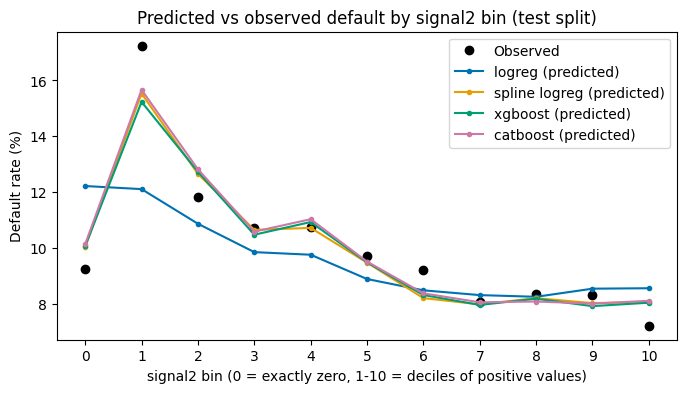

In [24]:
_, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_bin.index, by_bin["observed"], "o", color="black", label="Observed")
for name, color in zip(test_probs_no_dummy, COLORS):
    ax.plot(by_bin.index, by_bin[name], marker=".", color=color, label=f"{name} (predicted)")
ax.set(title="Predicted vs observed default by signal2 bin (test split)",
       xlabel="signal2 bin (0 = exactly zero, 1-10 = deciles of positive values)",
       ylabel="Default rate (%)", xticks=range(11))
ax.legend()
plt.show()

### Max PD

In [25]:
for name, p in test_probs_no_dummy.items():
    print(f"{name}: max PD {p.max():.2%}, borrowers with PD above 0.5: {(p > 0.5).sum()} / {len(p)}")

logreg: max PD 47.02%, borrowers with PD above 0.5: 0 / 30000
spline logreg: max PD 41.54%, borrowers with PD above 0.5: 0 / 30000
xgboost: max PD 38.34%, borrowers with PD above 0.5: 0 / 30000
catboost: max PD 44.06%, borrowers with PD above 0.5: 0 / 30000


- Out of fold, all four models are well calibrated: mean PD 9.94% to 9.96% vs 9.95% observed, slope 0.991 to 1.005, intercept close to 0.
- By `signal2` bin, logistic regression over-predicts at `signal2 = 0` (12.2% vs 9.3%) and under-predicts the riskiest bin (12.1% vs 17.2%). The other three models stay within 2 points in every bin.
- No model gives a PD above 0.5 to any test borrower (max 38% to 47%).

### Recalibration (D4)

No recalibration. Out-of-fold slope and intercept are already close to 1 and 0 for every model. The one gap found (logistic regression near `signal2 = 0`) is limited to a few bins, which a single global recalibration cannot fix.

## 11. Model selection (D5)

XGBoost has the lowest CV log loss (0.2907), but XGBoost, CatBoost and spline logistic regression are within one CV std of each other and equally well calibrated. Spline logistic regression is selected as the most explainable of the three: it keeps coefficients for the binary features and gives a curve for income and `signal2` that can be plotted, while the boosted models only give feature importances.

This follows the tie rule rather than the lowest-CV-log-loss rule used in signal1 and signal3. Since the three models give very similar PDs, the choice mainly affects the report.

In [26]:
selected = "spline logreg"
print(f"Selected model: {selected}")
comparison.loc[[selected]].round(4)

Selected model: spline logreg


,cv_log_loss,cv_std,log_loss,brier,auc
spline logreg,0.2913,0.001,0.2914,0.0838,0.7332


## 12. Export

Test split predictions of the selected model, trained on train only, in the agreed format `id, pd, pred, threshold`. The 0.5 threshold is for the format only; pricing uses `pd`. It is also where break-even needs a 100% rate, the maximum allowed, and no test borrower reaches it.

No refit on all data and no new-application predictions: new applicants have no `signal2`.

In [27]:
TAGS = {"logreg": "logreg", "spline logreg": "spline", "xgboost": "xgboost", "catboost": "catboost"}
tag = TAGS[selected]
THRESHOLD = 0.5


def prediction_table(ids: pd.Series, p: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame({"id": ids.to_numpy(), "pd": p, "pred": (p >= THRESHOLD).astype(int), "threshold": THRESHOLD})


test_predictions = prediction_table(test["id"], test_probs[selected])
test_path = PROCESSED_DIR / f"signal2_test_predictions_{tag}.csv"
test_predictions.to_csv(test_path, index=False)
print(f"{test_path.name}: {len(test_predictions):,} rows, {test_predictions['pred'].sum()} predicted defaults "
      f"at threshold {THRESHOLD}")

signal2_test_predictions_spline.csv: 30,000 rows, 0 predicted defaults at threshold 0.5


In [28]:
comparison.round(4).to_csv(PROCESSED_DIR / "signal2_metrics.csv", index_label="model")

best_settings = {
    "selected": selected,
    "logreg": final.best_params_,
    "spline logreg": spline_search.best_params_,
    "xgboost": {**xgb_study.best_params, "n_rounds": xgb_rounds},
    "catboost": {**cb_study.best_params, "n_rounds": cb_rounds},
}
(PROCESSED_DIR / "signal2_best_params.json").write_text(json.dumps(best_settings, indent=2))
print("Saved signal2_metrics.csv and signal2_best_params.json")

Saved signal2_metrics.csv and signal2_best_params.json


In [29]:
assert len(test_predictions) == 30_000, "expected 30,000 test rows"
assert set(test_predictions["id"]) == set(test["id"]), "test prediction ids do not match test.csv"
assert test_predictions["pd"].between(0, 1).all(), "pd must be between 0 and 1"
assert not test_predictions.isna().any().any(), "no missing values allowed"
mean_pd, true_rate = test_predictions["pd"].mean(), test[TARGET].mean()
assert abs(mean_pd - true_rate) < 0.02, f"mean pd {mean_pd:.2%} is far from the test default rate {true_rate:.2%}"
print(f"All checks passed. Mean predicted pd {mean_pd:.2%} vs test default rate {true_rate:.2%}.")

All checks passed. Mean predicted pd 9.96% vs test default rate 9.95%.
